# Wnioskowanie statystyczne: estymacja w Pythonie
**Workbook studenta | 180 minut | poziom podstawowy**

Zasada: **wykorzystujemy gotowe funkcje**, a czas przeznaczamy na interpretację. W ćwiczeniach uzupełniasz najczęściej jedną linię (`None` oznacza: odpowiedź jeszcze nieuzupełniona). Dwa rozwijane przyciski podpowiadają, jakich funkcji i argumentów użyć.

**Plan:** 0–15 intuicja · 15–35 losowanie · 35–70 CTG · 70–80 przerwa · 80–110 estymacja punktowa · 110–145 przedziały i precyzja · 145–170 projektowanie n · 170–180 dyskusja. Dane są syntetyczne.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import math

plt.style.use('seaborn-v0_8-whitegrid')
# Dane są syntetyczne. Ziarna pozwalają porównać wyniki w grupie.
pop_rng=np.random.default_rng(2026)
populacja=np.clip(pop_rng.lognormal(2.5,.48,100_000),1,80)
mu_pop=populacja.mean()  # W praktyce tego parametru nie znamy.
print('Środowisko gotowe!')


Środowisko gotowe!


## 0–35 min | Eksperyment: czy średnia próby jest stabilna?

Firma twierdzi, że realizacja zamówienia trwa średnio 13 godzin. Analityk z 20 obserwacji uzyskał 11,8 h. Czy możemy uznać, że proces przyspieszył?

**Zmieniaj dwa suwaki i klikaj „Losuj ponownie”.** Po lewej obserwujesz jedną próbę, po prawej rozkład średnich z kolejnych prób. Co zmienia liczebność? Co zmienia powtórzenie losowania?

In [3]:
# Wersja Jupyter z suwakami i przyciskiem; bez uzależniania pozostałych zadań od widżetów.
try:
    from IPython.display import display, clear_output
except ImportError:
    display=print
    def clear_output(wait=False):pass

def rysuj_losowania(n=30, liczba_losowan=20, seed=2026):
    local_rng=np.random.default_rng(seed)
    wszystkie_proby=local_rng.choice(populacja,size=(liczba_losowan,n),replace=True)
    pierwsza=wszystkie_proby[0]
    srednie=wszystkie_proby.mean(axis=1)
    fig,axs=plt.subplots(1,2,figsize=(12,4.2))
    axs[0].hist(pierwsza,bins=18,color='#00A99A',edgecolor='white',alpha=.86)
    axs[0].axvline(mu_pop,color='#10243B',ls='--',lw=2,label=f'Średnia populacji: {mu_pop:.2f} h')
    axs[0].axvline(pierwsza.mean(),color='#F59E42',lw=2,label=f'Średnia próby: {pierwsza.mean():.2f} h')
    axs[0].set(xlabel='Czas realizacji [h]',ylabel='Liczba zamówień',title=f'Pierwsza próba (n={n})')
    axs[0].legend(fontsize=8)

    if liczba_losowan==1:
        axs[1].scatter([srednie[0]],[0],s=100,color='#F59E42')
        axs[1].set(ylim=(-1,1),yticks=[])
    else:
        axs[1].hist(srednie,bins=min(18,max(5,liczba_losowan//3)),color='#00A99A',edgecolor='white')
    axs[1].axvline(mu_pop,color='#10243B',ls='--',lw=2)
    axs[1].set(xlabel='Średnia z próby [h]',ylabel='Liczba losowań',title=f'Średnie z {liczba_losowan} losowań')
    plt.tight_layout();plt.show()
    plt.close(fig)
    print(f'n={n}; losowań={liczba_losowan}; SD średnich={np.std(srednie,ddof=1):.3f} h' if liczba_losowan>1 else f'n={n}; pojedyncza średnia={srednie[0]:.2f} h')

try:
    import ipywidgets as widgets
except ImportError:
    print('Brak ipywidgets. W Jupyter zainstaluj pakiet: %pip install ipywidgets')
    print('Możesz już teraz zmieniać argumenty funkcji rysuj_losowania i uruchamiać ją ponownie:')
    rysuj_losowania(n=30,liczba_losowan=20,seed=2026)
else:
    n_slider=widgets.IntSlider(value=30,min=10,max=500,step=10,description='Próba n',continuous_update=False,style={'description_width':'95px'},layout=widgets.Layout(width='470px'))
    b_slider=widgets.IntSlider(value=20,min=1,max=100,step=1,description='Losowań',continuous_update=False,style={'description_width':'95px'},layout=widgets.Layout(width='470px'))
    losuj_btn=widgets.Button(description='🎲 Losuj ponownie',button_style='success',icon='refresh',layout=widgets.Layout(width='190px'))
    wynik=widgets.Output()
    stan={'iteracja':0}
    def pokaz(_=None):
        with wynik:
            clear_output(wait=True)
            rysuj_losowania(n_slider.value,b_slider.value,2026+stan['iteracja'])
    def nowe_losowanie(_):
        stan['iteracja']+=1
        pokaz()
    losuj_btn.on_click(nowe_losowanie)
    n_slider.observe(pokaz,names='value')
    b_slider.observe(pokaz,names='value')
    display(widgets.VBox([widgets.HBox([n_slider,b_slider]),losuj_btn,wynik]))
    pokaz()


## 35–70 min | CTG dla średniej i proporcji

Uruchom dwie demonstracje. Najpierw obserwujemy rozkład średnich z 1500 prób, potem rozkład proporcji dla danych zero-jedynkowych. Kod demonstracyjny jest gotowy, bo tutaj liczy się **zrozumienie zjawiska**.

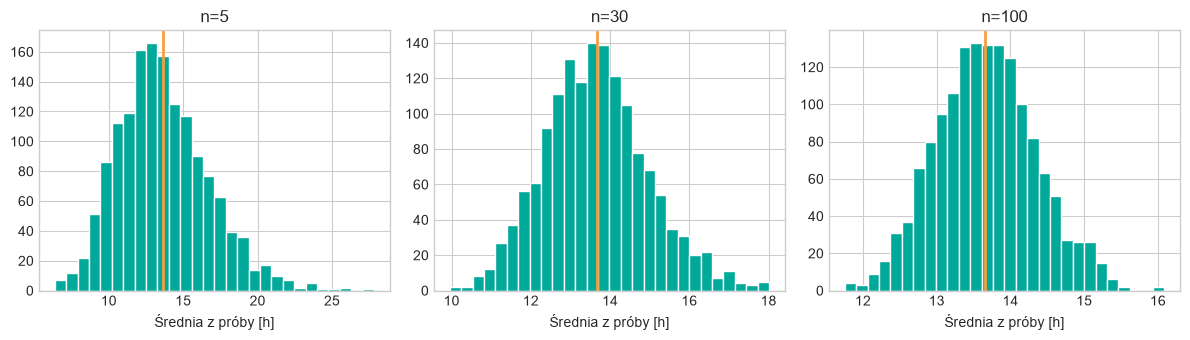

In [4]:
# DEMONSTRACJA: rozkład średnich z wielu prób
fig,axs=plt.subplots(1,3,figsize=(12,3.5))
for ax,n in zip(axs,[5,30,100]):
    local_rng=np.random.default_rng(900+n)
    samples=local_rng.choice(populacja,size=(1500,n),replace=True)
    means=samples.mean(axis=1)
    ax.hist(means,bins=28,color='#00A99A',edgecolor='white')
    ax.axvline(mu_pop,color='#F59E42',lw=2)
    ax.set(title=f'n={n}',xlabel='Średnia z próby [h]')
plt.tight_layout();plt.show()


**Zatrzymaj się:** dlaczego rozkład średniej staje się bardziej skupiony, choć rozkład pojedynczych obserwacji się nie zmienia? Jaką rolę odgrywa $\sqrt n$?

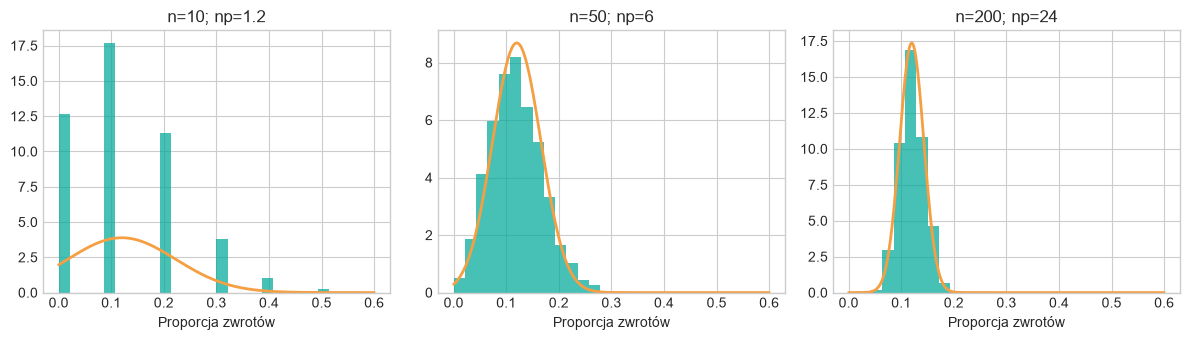

In [5]:
# DEMONSTRACJA: CTG dla proporcji (0/1)
p=0.12
fig,axs=plt.subplots(1,3,figsize=(12,3.5))
for ax,n in zip(axs,[10,50,200]):
    local_rng=np.random.default_rng(500+n)
    counts=local_rng.binomial(n,p,size=2000)
    proportions=counts/n
    ax.hist(proportions,bins=np.linspace(0,.6,29),density=True,
            color='#00A99A',alpha=.72)
    xx=np.linspace(0,.6,350)
    ax.plot(xx,stats.norm.pdf(xx,loc=p,scale=np.sqrt(p*(1-p)/n)),
            color='#F59E42',lw=2)
    ax.set(title=f'n={n}; np={n*p:g}',xlabel='Proporcja zwrotów')
plt.tight_layout();plt.show()


**Porównaj:** w jakiej sytuacji normalne przybliżenie proporcji jest słabe? Spójrz na przypadek $n=10$, $p=0{,}12$ i $np=1{,}2$. Zapisz dwa wnioski.

## 70–80 min | Przerwa

## 80–110 min | Estymacja punktowa z gotowymi funkcjami

Pracujemy na 40 czasach realizacji i 400 dostawach, wśród których wystąpiło 48 reklamacji. Wystarczy kilka funkcji: `np.mean()`, `np.std()`, `stats.sem()`.

In [6]:
# Jedne dane do wszystkich zadań. Nie zmieniaj ziarna: porównamy wyniki w grupie.
sample_rng=np.random.default_rng(12345)
czas=sample_rng.choice(populacja,size=40,replace=False)
reklamacje=48
dostawy=400
print('Liczba czasów:',len(czas),'| Reklamacje:',reklamacje,'na',dostawy,'dostaw')


Liczba czasów: 40 | Reklamacje: 48 na 400 dostaw


### Zadanie 1. Oszacowanie średniej i jej błąd standardowy

Uzupełnij dwie linie. Następnie odpowiedz: czym różni się odchylenie standardowe **czasów** od błędu standardowego **średniej**?

In [7]:
srednia = None # TODO: średnia z czas
se = None      # TODO: gotowy błąd standardowy średniej
if srednia is None or se is None:
    print('Uzupełnij średnią i SE.')
else:
    print(f'Średnia: {srednia:.2f} h; SE: {se:.2f} h')


Uzupełnij średnią i SE.


<details style="margin:10px 0;border:1px solid #9DCFC8;border-radius:10px;padding:9px;background:#F1FAF8">
<summary style="cursor:pointer;color:#08796F;font-weight:700">💡 Podpowiedź 1: gotowa funkcja</summary>

**NumPy:** `np.mean()`  ·  **SciPy:** `stats.sem()`
</details>

<details style="margin:10px 0;border:1px solid #F0D5A6;border-radius:10px;padding:9px;background:#FFFAF0">
<summary style="cursor:pointer;color:#9A5900;font-weight:700">🔎 Podpowiedź 2: jak jej użyć?</summary>

Wywołaj `np.mean(czas)` oraz `stats.sem(czas)`. Funkcja `sem()` uwzględnia poprawkę `ddof=1`.
</details>

### Zadanie 2. Udział reklamacji

Oblicz oszacowanie punktowe proporcji. Następnie powiedz menedżerowi, co oznacza ta liczba. Tu wystarczy dzielenie!

In [8]:
wynik = None # TODO: liczba reklamacji / liczba dostaw
if wynik is None:
    print('Uzupełnij jedno miejsce i uruchom ponownie.')
else:
    print('Wynik:',wynik)


Uzupełnij jedno miejsce i uruchom ponownie.


<details style="margin:10px 0;border:1px solid #9DCFC8;border-radius:10px;padding:9px;background:#F1FAF8">
<summary style="cursor:pointer;color:#08796F;font-weight:700">💡 Podpowiedź 1: gotowa funkcja</summary>

Proporcja to po prostu liczba sukcesów podzielona przez liczebność próby.
</details>

<details style="margin:10px 0;border:1px solid #F0D5A6;border-radius:10px;padding:9px;background:#FFFAF0">
<summary style="cursor:pointer;color:#9A5900;font-weight:700">🔎 Podpowiedź 2: jak jej użyć?</summary>

Wykorzystaj dostępne zmienne `reklamacje` i `dostawy`; zapis: `reklamacje/dostawy`.
</details>

## 110–145 min | Przedziały ufności bez ręcznego szukania kwantyli

Nie musisz sam wyliczać wartości krytycznej $t$. SciPy zrobi to za Ciebie. Twoim zadaniem jest właściwie podać: poziom ufności, liczbę stopni swobody, oszacowaną średnią i SE.

### Zadanie 3. Przedział 95% dla średniego czasu

Użyj gotowej funkcji. Następnie policz **margines błędu** jako połowę szerokości uzyskanego przedziału oraz **precyzję względną** względem oszacowania średniej.

In [9]:
ci_mean = None # TODO: gotowy przedział z scipy.stats
if ci_mean is None:
    print('Wyznacz przedział średniej.')
else:
    E=(ci_mean[1]-ci_mean[0])/2
    relative_E=E/abs(np.mean(czas))
    print(f'95% CI: [{ci_mean[0]:.2f}; {ci_mean[1]:.2f}] h')
    print(f'Margines błędu: ±{E:.2f} h; względny: {relative_E:.1%}')


Wyznacz przedział średniej.


<details style="margin:10px 0;border:1px solid #9DCFC8;border-radius:10px;padding:9px;background:#F1FAF8">
<summary style="cursor:pointer;color:#08796F;font-weight:700">💡 Podpowiedź 1: gotowa funkcja</summary>

**SciPy:** `stats.t.interval()` oraz `stats.sem()`.
</details>

<details style="margin:10px 0;border:1px solid #F0D5A6;border-radius:10px;padding:9px;background:#FFFAF0">
<summary style="cursor:pointer;color:#9A5900;font-weight:700">🔎 Podpowiedź 2: jak jej użyć?</summary>

Przekaż `confidence=.95`, `df=len(czas)-1`, `loc=np.mean(czas)` i `scale=stats.sem(czas)`.
</details>

### Zadanie 4. Przedział Wilsona dla udziału reklamacji

Wykorzystaj gotową metodę SciPy. Oblicz połowę szerokości przedziału **w punktach procentowych**. Dlaczego przy 12% lepiej zastosować Wilsona niż mechanicznie używać najprostszego przedziału Wald?

In [10]:
ci_prop = None # TODO: gotowy 95% przedział Wilsona
if ci_prop is None:
    print('Wyznacz przedział Wilsona.')
else:
    E_pp=(ci_prop.high-ci_prop.low)*100/2
    print(f'95% CI: [{ci_prop.low:.2%}; {ci_prop.high:.2%}]')
    print(f'Precyzja: ±{E_pp:.2f} p.p.')


Wyznacz przedział Wilsona.


<details style="margin:10px 0;border:1px solid #9DCFC8;border-radius:10px;padding:9px;background:#F1FAF8">
<summary style="cursor:pointer;color:#08796F;font-weight:700">💡 Podpowiedź 1: gotowa funkcja</summary>

**SciPy:** `stats.binomtest(...).proportion_ci()` — używamy tu wyłącznie części wyznaczającej przedział, bez testowania hipotez.
</details>

<details style="margin:10px 0;border:1px solid #F0D5A6;border-radius:10px;padding:9px;background:#FFFAF0">
<summary style="cursor:pointer;color:#9A5900;font-weight:700">🔎 Podpowiedź 2: jak jej użyć?</summary>

Przykładowe argumenty metody: `confidence_level=.95`, `method="wilson"`. Najpierw utwórz wynik `stats.binomtest(reklamacje,dostawy)`.
</details>

## 145–170 min | Jaka liczebność próby da wymaganą precyzję?

Przygotowujemy badanie, w którym margines błędu proporcji ma wynosić **±2 p.p.** przy 95% ufności. Funkcja pomocnicza poniżej wykonuje obliczenia za Ciebie. Korzysta z `stats.norm.ppf()` i zaokrągla w górę. Pamiętaj, że to **przybliżenie planistyczne**.

In [11]:
def potrzebna_proba_proporcji(p, precyzja=.02, ufnosc=.95):
    z=stats.norm.ppf((1+ufnosc)/2)
    return math.ceil(z**2 * p*(1-p) / precyzja**2)

def potrzebna_proba_sredniej(s_pilot, precyzja=1, ufnosc=.95):
    z=stats.norm.ppf((1+ufnosc)/2)
    return math.ceil((z*s_pilot/precyzja)**2)


### Zadanie 5. Liczebność próby dla proporcji

Użyj **tej samej gotowej funkcji** w dwóch wariantach: `p=0.12` (pilotaż) oraz `p=0.50` (brak wcześniejszej wiedzy). Porównaj wyniki i wyjaśnij, dlaczego się różnią.

In [12]:
n_pilot = None       # TODO: wywołaj potrzebna_proba_proporcji dla 12%
n_ostrozne = None    # TODO: wywołaj ją dla 50%
if n_pilot is None or n_ostrozne is None:
    print('Wywołaj funkcję dla obu wariantów.')
else:
    print('Próba z pilotażu:',n_pilot,'; konserwatywnie:',n_ostrozne)


Wywołaj funkcję dla obu wariantów.


<details style="margin:10px 0;border:1px solid #9DCFC8;border-radius:10px;padding:9px;background:#F1FAF8">
<summary style="cursor:pointer;color:#08796F;font-weight:700">💡 Podpowiedź 1: gotowa funkcja</summary>

Użyj zdefiniowanej wyżej funkcji **`potrzebna_proba_proporcji()`**.
</details>

<details style="margin:10px 0;border:1px solid #F0D5A6;border-radius:10px;padding:9px;background:#FFFAF0">
<summary style="cursor:pointer;color:#9A5900;font-weight:700">🔎 Podpowiedź 2: jak jej użyć?</summary>

Wywołaj ją z argumentem `p=.12`, a potem `p=.50`. Precyzja `.02` i ufność `.95` są już wartościami domyślnymi.
</details>

### Zadanie 6. Liczebność próby dla średniego czasu

Kierownik potrzebuje oszacowania średniego czasu realizacji z dokładnością **±1 h**. Użyj odchylenia standardowego z próby pilotażowej i naszej funkcji pomocniczej.

In [13]:
s_pilot = np.std(czas,ddof=1) # Odchylenie z pilotażu podajemy w godzinach.
n_czas = None # TODO: wywołaj potrzebna_proba_sredniej
if n_czas is None:
    print('Wywołaj funkcję dla s_pilot i precyzji 1 h.')
else:
    print('Orientacyjna minimalna liczebność:',n_czas)


Wywołaj funkcję dla s_pilot i precyzji 1 h.


<details style="margin:10px 0;border:1px solid #9DCFC8;border-radius:10px;padding:9px;background:#F1FAF8">
<summary style="cursor:pointer;color:#08796F;font-weight:700">💡 Podpowiedź 1: gotowa funkcja</summary>

Użyj funkcji **`potrzebna_proba_sredniej()`** z poprzedniej komórki.
</details>

<details style="margin:10px 0;border:1px solid #F0D5A6;border-radius:10px;padding:9px;background:#FFFAF0">
<summary style="cursor:pointer;color:#9A5900;font-weight:700">🔎 Podpowiedź 2: jak jej użyć?</summary>

Pierwszy argument to `s_pilot`; domyślna precyzja wynosi 1 godzinę, a ufność .95.
</details>

### Jak wygląda zależność precyzji od n?

Ten wykres jest już przygotowany, bo ważniejsze jest jego odczytanie niż ręczne budowanie. Ile razy należy zwiększyć próbę, aby zmniejszyć margines błędu dwukrotnie?

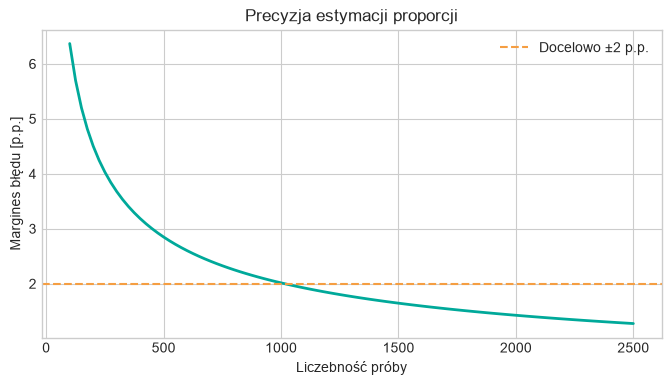

In [14]:
n_grid=np.arange(100,2501,25)
z=stats.norm.ppf(.975)
error=z*np.sqrt(.12*.88/n_grid)
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(n_grid,100*error,color='#00A99A',lw=2)
ax.axhline(2,color='#F59E42',ls='--',label='Docelowo ±2 p.p.')
ax.set(xlabel='Liczebność próby',ylabel='Margines błędu [p.p.]',title='Precyzja estymacji proporcji')
ax.legend();plt.show()


## 170–180 min | Podsumowanie i rozmowa

1. Jakimi dwiema funkcjami oszacujesz średnią i jej SE?
2. Kiedy użyjesz `stats.t.interval()` i kiedy `.proportion_ci(method="wilson")`?
3. Co oznacza margines błędu ±2 p.p.?
4. Dlaczego większa liczebność próby daje mniejszy błąd, ale nie zawsze proporcjonalnie do wzrostu kosztów?

**Twój mini-raport:** podaj oszacowanie punktowe, 95% CI, margines błędu i zaproponuj liczebność nowej próby. Wystarczy 5–6 zdań, bez testów hipotez.